## 1. Данные и задача

Источник: https://grouplens.org/datasets/hetrec-2011/, раздел **Last.FM**.

**Что рекомендуем:** 10 музыкальных исполнителей, которых нет в обучающей истории пользователя. Целевая переменная - бинарный факт взаимодействия пользователя с исполнителем: `y_ui = 1`, если число прослушиваний положительно. Отсутствие записи не означает отрицательную оценку. Задача - восстановить скрытые положительные взаимодействия, а не предсказать число прослушиваний.

Используем `user_artists.dat` (userID, artistID, weight - число прослушиваний) и `artists.dat` (id, name, url, pictureURL). Социальные связи и теги для минимального решения не нужны.

In [10]:
from pathlib import Path
from urllib.request import urlopen
import ssl
import certifi
import shutil
from zipfile import ZipFile
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from IPython.display import display
from implicit.als import AlternatingLeastSquares


SEED = 42
K = 10
DATA_DIR = Path("data") / "lastfm"
DATA_DIR.mkdir(parents=True, exist_ok=True)
archive = DATA_DIR / "hetrec2011-lastfm-2k.zip"
url = "https://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-2k.zip"
if not archive.exists():
    temporary = archive.with_suffix(".download")
    context = ssl.create_default_context()
    context.load_verify_locations(cafile=certifi.where())
    with urlopen(url, context=context, timeout=60) as response:
        with temporary.open("wb") as output:
            shutil.copyfileobj(response, output)
    temporary.replace(archive)

with ZipFile(archive) as z:
    with z.open("user_artists.dat") as f:
        raw = pd.read_csv(f, sep="\t")
    with z.open("artists.dat") as f:
        artists = pd.read_csv(f, sep="\t", encoding="utf-8", quoting=csv.QUOTE_NONE)

print("Прослушивания:", raw.shape)
display(raw.head())

print("Исполнители:", artists.shape)
display(artists.head())

Прослушивания: (92834, 3)


,userID,artistID,weight
0,2,51,13883
1,2,52,11690
2,2,53,11351
3,2,54,10300
4,2,55,8983


Исполнители: (17632, 4)


,id,name,url,pictureURL
0,1,MALICE MIZER,http://www.last.fm/music/MALICE+MIZER,http://userserve-ak.last.fm/serve/252/10808.jpg
1,2,Diary of Dreams,http://www.last.fm/music/Diary+of+Dreams,http://userserve-ak.last.fm/serve/252/3052066.jpg
2,3,Carpathian Forest,http://www.last.fm/music/Carpathian+Forest,http://userserve-ak.last.fm/serve/252/40222717...
3,4,Moi dix Mois,http://www.last.fm/music/Moi+dix+Mois,http://userserve-ak.last.fm/serve/252/54697835...
4,5,Bella Morte,http://www.last.fm/music/Bella+Morte,http://userserve-ak.last.fm/serve/252/14789013...


## 2. Качество данных и предобработка

Проверяем пропуски, точные дубли, повторные пары, некорректные идентификаторы и веса, связи без метаданных. Для выбросов используем верхнюю границу IQR. Большое число прослушиваний может быть реальным, поэтому положительные выбросы не удаляем. MostPop, UserKNN, ItemKNN и SVD используют бинарные взаимодействия. Для iALS сохраняем число прослушиваний и задаём уверенность как 1 + ln(1 + weight). Целевая переменная при оценке всех методов остаётся бинарной.

Удаляем строки с некорректными обязательными полями и точные дубли; повторные пары объединяем суммированием. Пропущенное имя заменяем обозначением ID. Пользователей с одной связью исключаем: невозможно оставить им одновременно train и test.

In [11]:
numeric = raw[["userID", "artistID", "weight"]].apply(pd.to_numeric, errors="coerce")
valid = (
    np.isfinite(numeric).all(axis=1)
    & numeric.gt(0).all(axis=1)
    & numeric[["userID", "artistID"]].mod(1).eq(0).all(axis=1)
)
positive_weights = numeric.loc[valid, "weight"]
q1, q3 = positive_weights.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
quality = pd.Series({
    "Строк исходно": len(raw),
    "Строк с пропусками": int(raw.isna().any(axis=1).sum()),
    "Точных дублей (сверх первого)": int(raw.duplicated().sum()),
    "Повторных пар пользователь - исполнитель": int(raw.duplicated(["userID", "artistID"]).sum()),
    "Некорректных обязательных полей": int((~valid).sum()),
    "Колличество прослушиваний выше верхней границы IQR": int((positive_weights > upper).sum()),
    "Связей с artistID без метаданных": int((~numeric.artistID.isin(artists.id)).sum()),
    "Повторных id в метаданных": int(artists.id.duplicated().sum()),
}, name="Количество")
display(quality.to_frame())
display(artists.isna().sum().rename("Пропуски в метаданных").to_frame())
print(f"Верхняя граница IQR для weight: {upper:.2f}")

clean = numeric.loc[valid].drop_duplicates().copy()
clean[["userID", "artistID"]] = clean[["userID", "artistID"]].astype("int64")
clean = clean.groupby(["userID", "artistID"], as_index=False)["weight"].sum()
counts = clean.groupby("userID").size()
excluded_users = int((counts < 2).sum())
df = clean[clean.userID.isin(counts[counts >= 2].index)].reset_index(drop=True)
artist_names = artists.drop_duplicates("id").set_index("id")["name"].dropna().to_dict()
def artist_name(artist_id):
    return artist_names.get(artist_id, f"Artist {artist_id}")

print(f"После очистки: {len(df):,} связей. Исключено пользователей с <2 связями: {excluded_users}.")

,Количество
Строк исходно,92834
Строк с пропусками,0
Точных дублей (сверх первого),0
Повторных пар пользователь - исполнитель,0
Некорректных обязательных полей,0
Колличество прослушиваний выше верхней границы IQR,9404
Связей с artistID без метаданных,0
Повторных id в метаданных,0


,Пропуски в метаданных
id,0
name,0
url,0
pictureURL,444


Верхняя граница IQR для weight: 1374.50
После очистки: 92,826 связей. Исключено пользователей с <2 связями: 8.


,Значение
Пользователей,1884.000000
Исполнителей,17626.000000
Взаимодействий,92826.000000
Разреженность,0.997205


,Исполнителей на пользователя,Пользователей на исполнителя,Прослушиваний на пару
count,1884.000000,17626.000000,92826.000000
mean,49.270701,5.266425,744.867796
std,4.945907,20.622008,3749.816771
min,2.000000,1.000000,1.000000
25%,50.000000,1.000000,107.000000
50%,50.000000,1.000000,260.000000
75%,50.000000,3.000000,614.000000
max,50.000000,610.000000,352698.000000


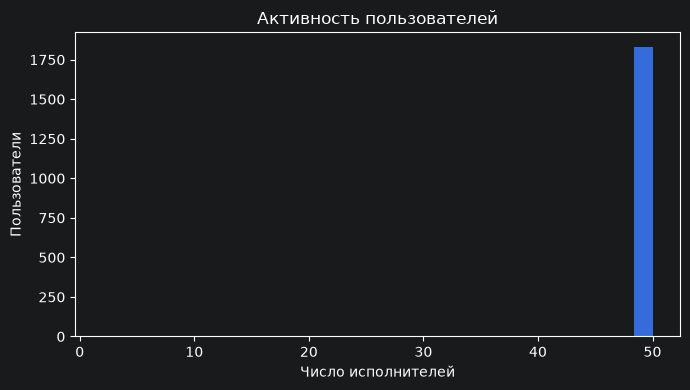

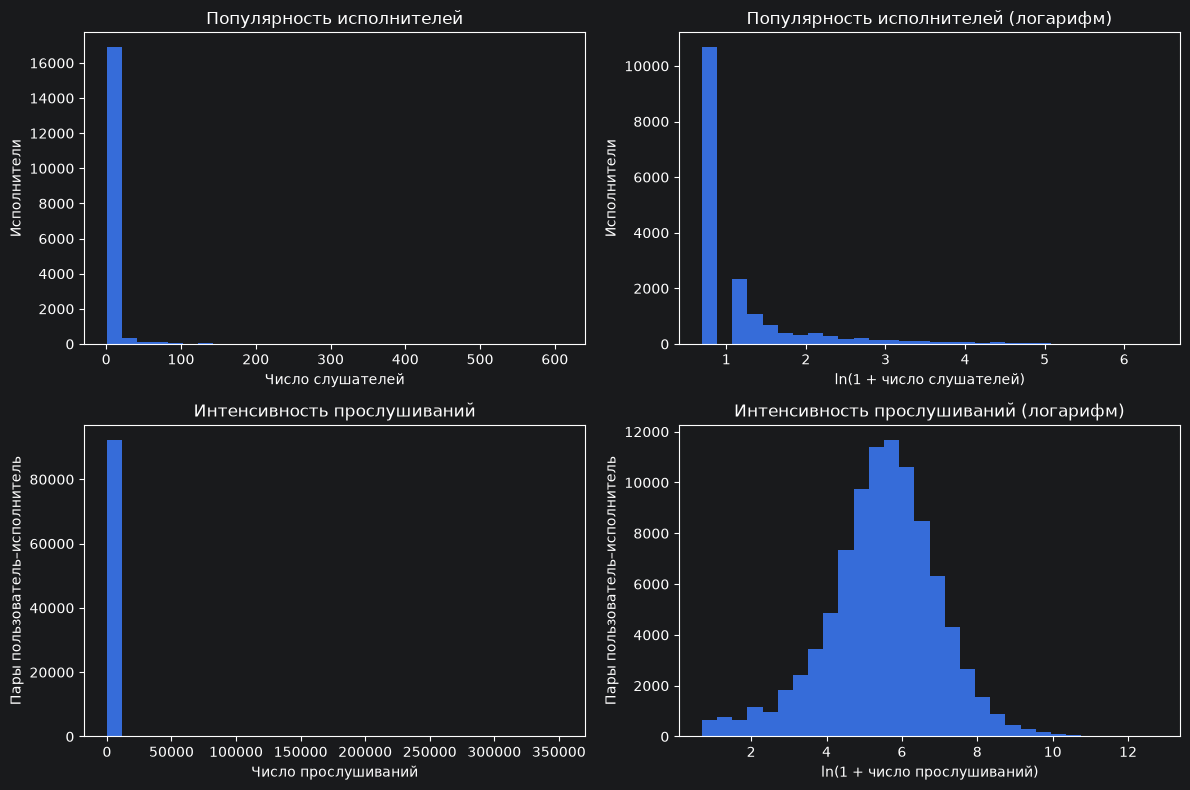

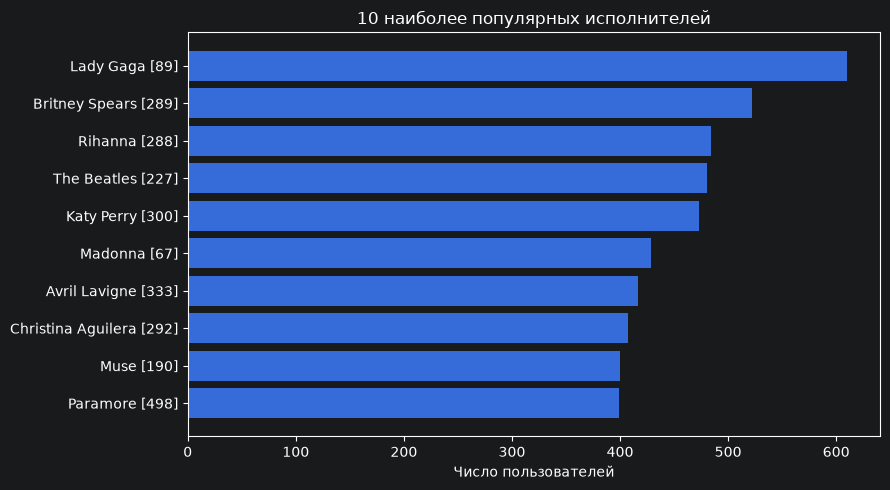

In [12]:
user_counts = df.groupby("userID").size()
item_counts = df.groupby("artistID").size()
n_users, n_items = len(user_counts), len(item_counts)
sparsity = 1 - len(df) / (n_users * n_items)
display(pd.Series({
    "Пользователей": n_users,
    "Исполнителей": n_items,
    "Взаимодействий": len(df),
    "Разреженность": sparsity,
}, name="Значение").to_frame())
display(pd.DataFrame({
    "Исполнителей на пользователя": user_counts.describe(),
    "Пользователей на исполнителя": item_counts.describe(),
    "Прослушиваний на пару": df.weight.describe(),
}))

plt.figure(figsize=(7, 4))
plt.hist(user_counts, bins=30)
plt.title("Активность пользователей")
plt.xlabel("Число исполнителей")
plt.ylabel("Пользователи")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(item_counts, bins=30)
axes[0, 0].set(title="Популярность исполнителей", xlabel="Число слушателей", ylabel="Исполнители")
axes[0, 1].hist(np.log1p(item_counts), bins=30)
axes[0, 1].set(title="Популярность исполнителей (логарифм)", xlabel="ln(1 + число слушателей)", ylabel="Исполнители")

axes[1, 0].hist(df.weight, bins=30)
axes[1, 0].set(title="Интенсивность прослушиваний", xlabel="Число прослушиваний", ylabel="Пары пользователь–исполнитель")
axes[1, 1].hist(np.log1p(df.weight), bins=30)
axes[1, 1].set(title="Интенсивность прослушиваний (логарифм)", xlabel="ln(1 + число прослушиваний)", ylabel="Пары пользователь–исполнитель")
plt.tight_layout()
plt.show()

top = item_counts.nlargest(10).sort_values()
plt.figure(figsize=(9, 5))
plt.barh([f"{artist_name(i)} [{i}]" for i in top.index], top.values)
plt.xlabel("Число пользователей")
plt.title("10 наиболее популярных исполнителей")
plt.tight_layout()
plt.show()

top_share = item_counts.nlargest(10).sum() / len(df)
rare_share = (item_counts <= 5).mean()

Данных для рекомендаций много в абсолютных числах, но по большинству исполнителей слушателей мало.
1. Разреженность - 99,72%. В df есть 92826 пар «пользователь - исполнитель». Если взять всех пользователей и всех исполнителей, запись есть примерно для 3 из 1000 возможных пар. Для UserKNN важны совпадения в историях, поэтому при малом числе общих исполнителей оценка сходства опирается на мало примеров.
2. Медиана - 50 исполнителей на пользователя. На графике активности видно, что большинство историй сосредоточено около 50, и это же максимум в нашей таблице. Такой пик стоит описывать как свойство выгрузки. По нему нельзя судить о том, сколько исполнителей люди слушали за всё время.
3. У 86,3% исполнителей не больше пяти слушателей. При этом на десять самых популярных приходится 5% всех пар. Эти числа отвечают на разные вопросы: первое говорит, насколько много редких исполнителей в каталоге, а второе - какую долю записей собирает верхушка рейтинга. Для редкого исполнителя у UserKNN мало возможностей найти соседа, который за него «проголосует».
4. Число прослушиваний сильно различается. Медиана - 260 на пару, а максимум - 352698. Поэтому на линейном графике основная масса значений сжимается слева, а на графике с логарифмом её легче рассмотреть. По правилу IQR мы отметили 9404 больших значения и сохранили их. Такие числа могут отражать реальные прослушивания. MostPop, UserKNN, ItemKNN и SVD используют сам факт связи с исполнителем. iALS дополнительно учитывает число прослушиваний через уверенность 1 + ln(1 + weight).

## 3. Обучающая и тестовая выборки

Для каждого пользователя случайно скрываем 20% исполнителей с округлением вниз, минимум одного. Остальные записи оставляем в train. Фиксируем SEED = 42. В таблице прослушиваний нет времени событий, поэтому оцениваем восстановление случайно скрытой истории.

Все модели и популярности обучаются только на train. Кандидаты - исполнители с хотя бы одной связью в train, кроме уже известных пользователю. Исполнители только из test остаются в знаменателе Recall и идеальном ранжировании NDCG: такие случаи не скрываем и отдельно считаем.

In [13]:
rng = np.random.default_rng(SEED)
test_indices = []

for _, group in df.groupby("userID", sort=True):
    n_test = max(1, int(len(group) * 0.2))
    chosen = rng.choice(group.index, size=n_test, replace=False)
    test_indices.extend(chosen)

train = df.drop(index=test_indices).copy()
test = df.loc[test_indices].copy()

cold_test = ~test.artistID.isin(train.artistID)
display(pd.DataFrame({
    "Выборка": ["train", "test"],
    "Связей": [len(train), len(test)],
    "Пользователей": [train.userID.nunique(), test.userID.nunique()],
    "Исполнителей": [train.artistID.nunique(), test.artistID.nunique()],
}))
print(f"Связей test с неизвестным в train исполнителем: {cold_test.sum()} ({cold_test.mean():.2%})")

,Выборка,Связей,Пользователей,Исполнителей
0,train,74279,1884,15409
1,test,18547,1884,6371


Связей test с неизвестным в train исполнителем: 2331 (12.57%)


In [14]:
users = np.sort(df.userID.unique())
items = np.sort(df.artistID.unique())
user_to_idx = {v: i for i, v in enumerate(users)}
item_to_idx = {v: i for i, v in enumerate(items)}

rows = train.userID.map(user_to_idx)
cols = train.artistID.map(item_to_idx)
values = np.ones(len(train), dtype=np.float32)

X = csr_matrix((values, (rows, cols)), shape=(len(users), len(items)))

popularity = np.asarray(X.sum(axis=0)).ravel()
catalog_mask = popularity > 0
truth = {
    user_to_idx[u]: set(group.artistID.map(item_to_idx))
    for u, group in test.groupby("userID")
}

print("Число исполнителей в каталоге рекомендаций:", catalog_mask.sum())

Число исполнителей в каталоге рекомендаций: 15409


## 4. Методы рекомендаций

1. **MostPop:** неперсонализированный baseline; ранжируем по числу пользователей в train.
2. **UserKNN:** соседский метод; косинусная близость бинарных историй пользователей, до 40 ближайших соседей. Оценка исполнителя - сумма близостей соседей, слушавших его.
3. **ItemKNN:** ищет похожих исполнителей по общим слушателям. Балл кандидата — сумма сходств с исполнителями из истории пользователя.
4. **TruncatedSVD:** факторизация бинарной матрицы с 32 компонентами. Пропуски представлены нулями.
5. **iALS:** факторизация для неявной обратной связи. Использует 1 + ln(1 + число прослушиваний) как вес уверенности в положительном интересе. Заданы 32 фактора, регуляризация 0,1 и 15 итераций. Параметры выбраны заранее без подбора по test.

При равных оценках используем популярность train, затем индекс исполнителя. Из рекомендаций всех моделей исключаем обучающую историю.

In [15]:
from sklearn.metrics.pairwise import cosine_similarity

# UserKNN: находим до 40 похожих слушателей для каждого пользователя.
n_users = X.shape[0]
neighbors = min(40, n_users - 1)

similarity = cosine_similarity(X)
np.fill_diagonal(similarity, 0)

neighbor_idx = np.argsort(-similarity, axis=1, kind="stable")[:, :neighbors]
rows = np.repeat(np.arange(n_users), neighbors)
cols = neighbor_idx.ravel()
weights = similarity[rows, cols]

# W[u, v] — вес голоса соседа v для пользователя u.
W = csr_matrix((weights, (rows, cols)), shape=(n_users, n_users))
W.eliminate_zeros()
del similarity

# ItemKNN: похожесть исполнителей по общим слушателям.
item_similarity = cosine_similarity(X.T, dense_output=False).tocsr()
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()
item_rows, item_cols, item_weights = [], [], []
item_neighbors = min(40, X.shape[1] - 1)
for item_idx in range(X.shape[1]):
    start, end = item_similarity.indptr[item_idx:item_idx + 2]
    row_items = item_similarity.indices[start:end]
    row_scores = item_similarity.data[start:end]
    top = np.argsort(-row_scores, kind="stable")[:item_neighbors]
    item_rows.extend([item_idx] * len(top))
    item_cols.extend(row_items[top])
    item_weights.extend(row_scores[top])
W_items = csr_matrix((item_weights, (item_rows, item_cols)), shape=(X.shape[1], X.shape[1]))
del item_similarity

# iALS: число прослушиваний задаёт уверенность в положительном взаимодействии.
confidence = 1 + np.log1p(train.weight.to_numpy(dtype=np.float32))
X_confidence = csr_matrix(
    (confidence, (train.userID.map(user_to_idx), train.artistID.map(item_to_idx))),
    shape=X.shape,
)
ials = AlternatingLeastSquares(factors=32, regularization=0.1, iterations=15, random_state=SEED)
ials.fit(X_confidence)
# SVD: строим числовые представления пользователей и исполнителей.
n_components = min(32, min(X.shape) - 1)
svd = TruncatedSVD(n_components=n_components, random_state=SEED)
user_factors = svd.fit_transform(X)
item_factors = svd.components_

print(f"UserKNN: до {neighbors} соседей. SVD: {n_components} факторов.")

def recommend(user_idx, method, k=K):
    if method == "MostPop":
        scores = popularity.copy()
    elif method == "UserKNN":
        scores = (W.getrow(user_idx) @ X).toarray().ravel()
    elif method == "ItemKNN":
        scores = (X.getrow(user_idx) @ W_items).toarray().ravel()
    elif method == "iALS":
        item_ids, item_scores = ials.recommend(user_idx, X.getrow(user_idx), N=X.shape[1], filter_already_liked_items=False, recalculate_user=False)
        scores = np.full(X.shape[1], -np.inf)
        scores[item_ids] = item_scores
    elif method == "SVD":
        scores = user_factors[user_idx] @ item_factors
    else:
        raise ValueError(method)
    allowed = catalog_mask.copy()
    allowed[X.getrow(user_idx).indices] = False
    candidates = np.flatnonzero(allowed)
    order = np.lexsort((candidates, -popularity[candidates], -scores[candidates]))
    return candidates[order[:k]]

100%|██████████| 15/15 [00:00<00:00, 35.50it/s]


UserKNN: до 40 соседей. SVD: 32 факторов.


## 5. Метрики и сравнение

Для каждого пользователя Rᵤ — список рекомендаций, Tᵤ — скрытые положительные взаимодействия, hᵤ = |Rᵤ ∩ Tᵤ| — число попаданий. K = 10. Каждую метрику усредняем по пользователям, так что все пользователи имеют одинаковый вес.

- **Precision@10** = hᵤ / 10. Доля рекомендаций, совпавших со скрытой историей.
- **Recall@10** = hᵤ / |Tᵤ|. Доля найденных скрытых исполнителей.
- **NDCG@10** учитывает позиции попаданий. За попадание на позиции r начисляем 1 / log₂(r + 1), за промах — 0. Складываем баллы первых десяти позиций и делим на сумму для идеального списка с min(10, |Tᵤ|) попаданиями в начале. Значение находится от 0 до 1.
- **Novelty@10** — среднее −log₂(pᵢ) по рекомендованным исполнителям, где pᵢ = число слушателей исполнителя в train / число пользователей train. Измеряется в битах. Чем выше значение, тем менее популярных исполнителей предлагает метод. Это показатель новизны через редкость, который сам по себе не гарантирует полезность рекомендаций.

Основная метрика сравнения — NDCG@10. Более высокие Precision, Recall и NDCG означают лучшее восстановление скрытой истории. Новизну оцениваем вместе с этими метриками.

,Precision@10,Recall@10,NDCG@10,Novelty@10
Метод,,,,
MostPop,0.0687,0.0694,0.0802,2.4452
UserKNN,0.1649,0.1673,0.2015,3.6221
ItemKNN,0.1444,0.1466,0.1820,5.4134
SVD,0.1544,0.1571,0.1870,3.9161
iALS,0.1925,0.1960,0.2321,4.2274


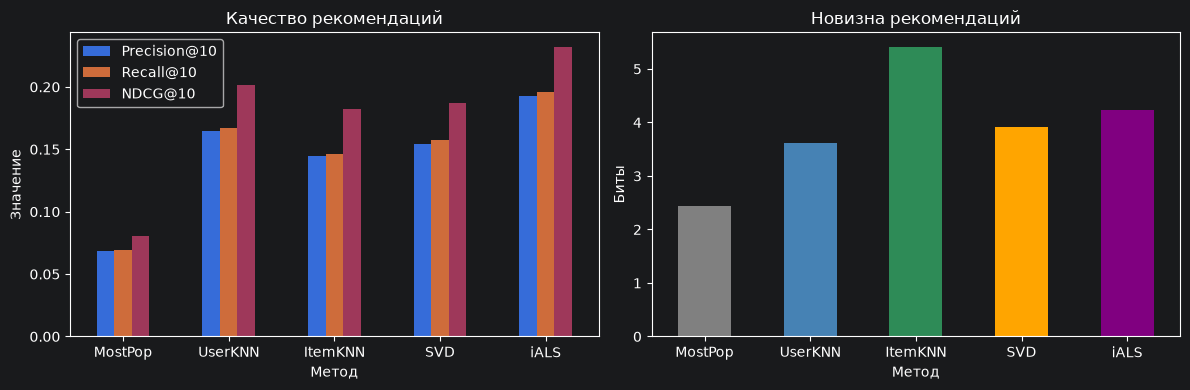

In [16]:
discounts = 1 / np.log2(np.arange(2, K + 2))
novelty = np.zeros(len(items), dtype=float)
novelty[catalog_mask] = -np.log2(popularity[catalog_mask] / X.shape[0])
recommendations = {}
result_rows = []

for method in ["MostPop", "UserKNN", "ItemKNN", "SVD", "iALS"]:
    per_user = []
    recommendations[method] = {}
    for u, relevant in truth.items():
        rec = recommend(u, method)
        recommendations[method][u] = rec
        hits = np.array([i in relevant for i in rec], dtype=float)
        ideal = discounts[:min(K, len(relevant))].sum()
        per_user.append([
            hits.sum() / K,
            hits.sum() / len(relevant),
            (hits * discounts).sum() / ideal,
            novelty[rec].mean(),
        ])
    result_rows.append(np.mean(per_user, axis=0))

results = pd.DataFrame(
    result_rows, index=["MostPop", "UserKNN", "ItemKNN", "SVD", "iALS"],
    columns=["Precision@10", "Recall@10", "NDCG@10", "Novelty@10"],
)
results.index.name = "Метод"
display(results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results.iloc[:, :3].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Качество рекомендаций", ylabel="Значение")
results["Novelty@10"].plot.bar(ax=axes[1], rot=0, color=["gray", "steelblue", "seagreen", "orange", "purple"])
axes[1].set(title="Новизна рекомендаций", ylabel="Биты")
plt.tight_layout()
plt.show()

### Пример рекомендаций

Показываем одного пользователя из test.

In [17]:
example_u = min(truth)
seen = X.getrow(example_u).indices
print("Пользователь:", users[example_u])
print("Примеры исполнителей из train:", ", ".join(str(artist_name(items[i])) for i in seen[:10]))
example_rows = []
for method, user_recs in recommendations.items():
    for rank, i in enumerate(user_recs[example_u], start=1):
        example_rows.append({
            "Метод": method, "Место": rank,
            "Исполнитель": artist_name(items[i]), "В test": i in truth[example_u],
        })
display(pd.DataFrame(example_rows))

Пользователь: 2
Примеры исполнителей из train: Duran Duran, Morcheeba, Air, Daft Punk, Thievery Corporation, Goldfrapp, New Order, Talk Talk, Prefab Sprout, Enigma


,Метод,Место,Исполнитель,В test
0,MostPop,1,Britney Spears,False
1,MostPop,2,Rihanna,False
2,MostPop,3,The Beatles,False
3,MostPop,4,Katy Perry,False
4,MostPop,5,Avril Lavigne,False
5,MostPop,6,Christina Aguilera,False
6,MostPop,7,Muse,False
7,MostPop,8,Beyoncé,False
8,MostPop,9,Paramore,False
9,MostPop,10,Radiohead,False


## 6. Итоговые выводы

На сохранённом разбиении лучший результат показал **iALS**. По NDCG он превосходит UserKNN.

**UserKNN** занимает второе место по метрикам попаданий, все четыре персонализированных метода превзошли базовые рекомендации по популярности.

**ItemKNN** показал наибольшую новизну. Он рекомендует менее популярных исполнителей, но уступает UserKNN по точности. iALS сочетает лучшие метрики попаданий с новизной, превышающей новизну UserKNN и SVD.

iALS использует дополнительную информацию о числе прослушиваний. Поэтому сравнение относится к алгоритмам вместе с выбранной подготовкой данных. Чтобы отдельно оценить пользу весов, нужен дополнительный эксперимент с бинарным и взвешенным iALS.

Ограничения эксперимента

- Использовано одно случайное разбиение. Статистическая значимость различий не проверялась. Из-за отсутствия времени событий оцениваем восстановление истории.
- Пользователи без обучающей истории не оценивались. Отсутствие исполнителя в test означает отсутствие подтверждённого попадания, а его интересность для пользователя остаётся неизвестной.
